### Analisis 02 del E-Commerce Business Analysis

In [15]:
# Library
import pandas as pd
import matplotlib.pyplot as plt
import datetime as dt
import numpy as np
import scipy.stats
from sklearn.metrics import mean_squared_error
from math import sqrt
import os
from os import listdir
from datetime import datetime
import pandas as pd
from matplotlib.dates import DateFormatter
import matplotlib.ticker as ticker
import matplotlib.dates as mdates
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
import seaborn as sn
import plotly.express as px
import kagglehub
import seaborn as sns
print("listo ok")

listo ok


In [3]:
# El link se saca de lo que me dice kaggle antes
df = pd.read_csv("C:/Users/Josefina Urquiza/.cache/kagglehub/datasets/umuttuygurr/e-commerce-customer-behavior-and-sales-analysis-tr/versions/2/ecommerce_customer_behavior_dataset_v2.csv")

df

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,29.18,Digital Wallet,Mobile,14,9,True,13,4
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,506.35,Credit Card,Desktop,14,8,True,6,2
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,1664.10,Credit Card,Mobile,15,10,True,9,4
3,ORD_000002-1,CUST_00002,2023-05-11,33,Male,Istanbul,Food,69.30,5,71.05,275.45,Digital Wallet,Desktop,16,13,True,4,4
4,ORD_000002-2,CUST_00002,2023-06-16,33,Male,Istanbul,Beauty,178.15,3,0.00,534.45,Credit Card,Mobile,14,7,True,6,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17044,ORD_004999-1,CUST_04999,2024-01-16,44,Male,Antalya,Beauty,68.65,2,0.00,137.30,Digital Wallet,Mobile,14,10,False,6,1
17045,ORD_005000-1,CUST_05000,2023-02-22,24,Female,Eskisehir,Beauty,156.12,1,0.00,156.12,Credit Card,Mobile,15,8,True,7,5
17046,ORD_005000-2,CUST_05000,2023-06-29,24,Female,Eskisehir,Home & Garden,1065.24,3,0.00,3195.72,Credit Card,Desktop,17,11,True,5,4
17047,ORD_005000-3,CUST_05000,2023-12-29,24,Female,Eskisehir,Books,47.73,2,8.80,86.66,Credit Card,Desktop,13,11,True,12,2


####  01. Definicion del problema: 

El objetivo de este análisis es identificar los factores que influyen tanto en la recompra como en la facturación por compra, con el fin de comprender qué variables impulsan la rentabilidad del negocio.

A través del análisis de variables demográficas, de comportamiento de compra, comportamiento digital y experiencia post-compra, se buscará determinar qué características están asociadas a:

- Mayor probabilidad de volver a c.
- Mayor nivel de facturación por compra (Total_Amount).

Este conocimiento permitirá orientar decisiones comerciales, optimizar estrategias de retención y maximizar el valor generado por cada cliente.

## 02. Enfoque analítico

Dado que el objetivo es identificar los factores asociados a la recompra y a la facturación por compra, el análisis se estructurará en dos bloques:

- Variables de recompra.
- Variables de facturación por compra.

En ambos casos se explorarán relaciones entre variables demográficas, de comportamiento de compra, digitales y de experiencia post-compra.

BLOQUE 1: Variables de recompra

### Variable objetivo: Is_Returning_Customer

Algunas preguntas:
- Los clientes recurrentes gastan más por compra?
- Tienen mejor rating?
- Sufren menos demoras?
- Usan más Mobile o Desktop?
- Compran ciertas categorías más que otras?
- Reciben más o menos descuentos?

                              mean   median          std  count
Is_Returning_Customer                                          
False                  1287.727428  456.115  2426.429676   2010
True                   1276.063599  455.850  2349.279116  15039


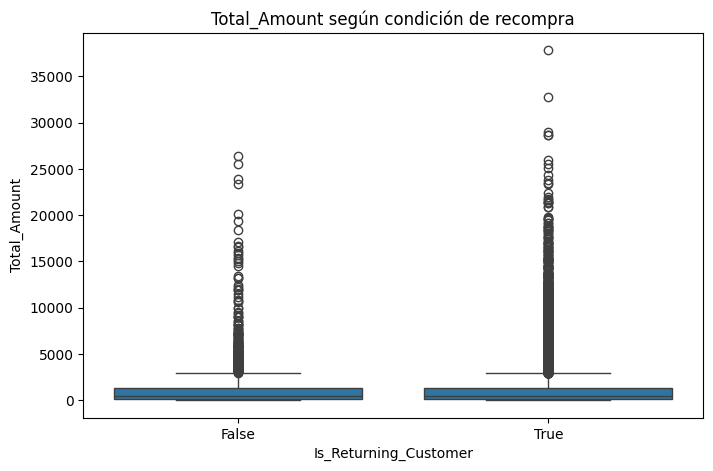

In [4]:
# Recompra vs Facturación
# Queremos ver si los clientes recurrentes generan mayor ticket.

print(df.groupby("Is_Returning_Customer")["Total_Amount"].agg(["mean", "median", "std", "count"]))

plt.figure(figsize=(8,5))
sns.boxplot(x="Is_Returning_Customer", y="Total_Amount", data=df)
plt.title("Total_Amount según condición de recompra")
plt.show()

Resumen:
- La media es prácticamente igual, no es relevante económicamente.
- La mediana es prácticamente idéntica. La mediana representa el comportamiento típico lo que significa que el ticket típico es el mismo en ambos grupos.
- Alta dispersión en ambos grupos. Existen compras muy grandes en ambos grupos. Pero la dispersión también es similar.
- Hay diferencia entre el numero de recurrentes y no, lo que implica que el negocio está dominado por clientes recurrentes.
- La recompra no parece estar asociada a un mayor nivel de facturación por compra.
- La rentabilidad de los clientes recurrentes probablemente esté explicada por la frecuencia de compra, y no por un mayor gasto individual.

### Variable objetivo: Recompra vs Tiempo de entrega
- Menor tiempo de entrega aumenta la probabilidad de recompra


Is_Returning_Customer
False    6.415423
True     6.515393
Name: Delivery_Time_Days, dtype: float64


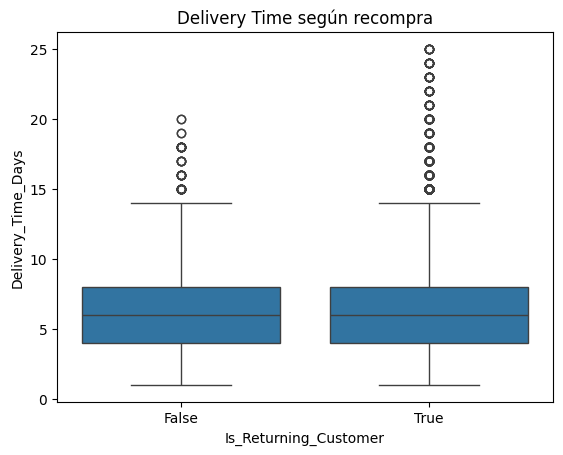

In [5]:
print(df.groupby("Is_Returning_Customer")["Delivery_Time_Days"].mean())

sns.boxplot(x="Is_Returning_Customer", y="Delivery_Time_Days", data=df)
plt.title("Delivery Time según recompra")
plt.show()

In [6]:
# Los tiempos extremos afectan la recompra?
df["Late_Delivery"] = (df["Delivery_Time_Days"] > 10).astype(int)

pd.crosstab(df["Late_Delivery"], df["Is_Returning_Customer"], normalize="index")

Is_Returning_Customer,False,True
Late_Delivery,,
0,0.116944,0.883056
1,0.124166,0.875834


Resumen
- Las medias son prácticamente iguales.  La diferencia es mínima (0.10 días), lo que no tiene impacto real.
- Recurrentes incluso tienen un tiempo levemente mayor.
- No se observan diferencias significativas en el tiempo de entrega promedio entre clientes recurrentes y no recurrentes.
- Esto sugiere que, el tiempo de entrega no es un factor determinante en la recompra.
- La fidelidad del cliente podría estar más influenciada por otros factores distintos a la logística.
- Los tiempos extremos no afectan la recompra, es minimo
- No se observa una diferencia significativa en la tasa de recompra entre órdenes con entrega tardía y órdenes sin retraso.
- La proporción de clientes recurrentes se mantiene prácticamente estable en ambos grupos.
- Esto sugiere que, en este dataset, los retrasos moderados no parecen afectar de manera relevante la fidelización.

### Variable objetivo: Recompra vs Customer_Rating
- Una mayor satisfacción del cliente aumenta la probabilidad de recompra?
- Los clientes más satisfechos vuelven a comprar más?


Is_Returning_Customer
False    3.877612
True     3.902321
Name: Customer_Rating, dtype: float64


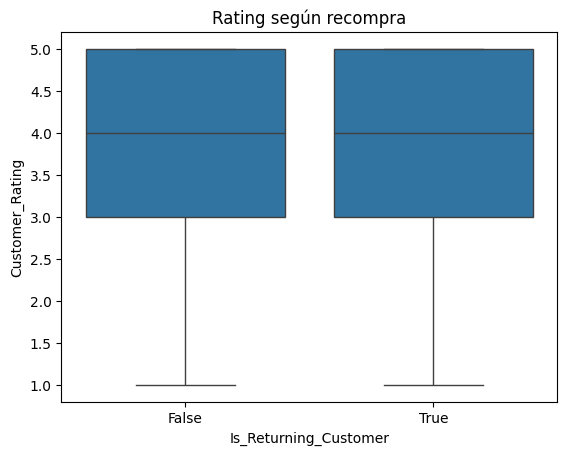

In [7]:
print(df.groupby("Is_Returning_Customer")["Customer_Rating"].mean())

sns.boxplot(x="Is_Returning_Customer", y="Customer_Rating", data=df)
plt.title("Rating según recompra")
plt.show()

Resumen
- Los clientes recurrentes presentan un rating promedio levemente superior.
- Sin embargo, la diferencia es mínima y no parece tener relevancia práctica.
- No se observa una separación clara entre ambos grupos en la distribución.
- Esto sugiere que la satisfacción medida por el rating no es un factor determinante en la recompra dentro de este dataset.

### Variable objetivo: Recompra vs Comportamiento Digital

- El tipo de dispositivo influye en la probabilidad de recompra?
- La proporción de clientes recurrentes cambia según el Device_Type?

In [11]:
pd.crosstab(df["Device_Type"], df["Is_Returning_Customer"], normalize="index")

Is_Returning_Customer,False,True
Device_Type,,
Desktop,0.115141,0.884859
Mobile,0.118621,0.881379
Tablet,0.123420,0.876580


Resumen
- La recompra es altísima en todos los dispositivos (~88%).
- Las diferencias entre dispositivos son mínimas (menos de 1%).
- No hay un patrón claro que diga “tal dispositivo genera más fidelidad”.

### Variable objetivo: Recompra vs Session_Duration
- El tiempo que el usuario pasa en el sitio está asociado a la recompra?
- Los clientes recurrentes navegan más tiempo?
- Los que no vuelven tienen sesiones más cortas?
- Hay señales de mayor engagement digital en quienes recompran? 

In [8]:
df.groupby("Is_Returning_Customer")["Session_Duration_Minutes"].mean()

Is_Returning_Customer
False    14.482090
True     14.542789
Name: Session_Duration_Minutes, dtype: float64

Resumen 
- La diferencia es prácticamente nula.
- Esta variable no parece  explicar la recompra.
- El tiempo promedio de navegación es similar para todos, no importa si vuelven o no

### Variable objetivo: Recompra vs Pages_Viewed
- Los clientes que vuelven navegan más páginas durante la sesión que los que no vuelven?
- El nivel de exploración digital está asociado a la recompra?

In [15]:
df.groupby("Is_Returning_Customer")["Pages_Viewed"].mean()

Is_Returning_Customer
False    8.930348
True     9.012833
Name: Pages_Viewed, dtype: float64

Resumen
- La cantidad promedio de páginas vistas es prácticamente igual entre ambos grupos.
- No se observa una diferencia relevante en el nivel de navegación.
- El comportamiento digital medido por exploración no parece estar asociado a la recompra.
- La recompra no depende de que el usuario “navegue más”.
- Los clientes recurrentes no necesitan explorar más.

### Variable objetivo:  Recompra vs Categoría

- Hay categorías que generen mayor proporción de clientes recurrentes?
- El tipo de producto influye en la fidelidad?

In [ ]:
# Esto te muestra qué categorías tienen mayor proporción de clientes recurrentes
pd.crosstab(df["Product_Category"], df["Is_Returning_Customer"], normalize="index")

Is_Returning_Customer,False,True
Product_Category,,
Beauty,0.115732,0.884268
Books,0.120127,0.879873
Electronics,0.119576,0.880424
Fashion,0.120623,0.879377
Food,0.112221,0.887779
Home & Garden,0.113107,0.886893
Sports,0.116103,0.883897
Toys,0.125837,0.874163


Resumen:
- Todas las categorías tienen aproximadamente tienen entre 87% - 89% de clientes recurrentes
- Diferencias máximas de apenas ~1,3 puntos porcentuales
- No hay una categoría que destaque claramente en fidelidad.
- La tasa de recompra es alta y bastante homogénea.
- La variación entre categorías es mínima.
- El tipo de producto no parece ser un driver fuerte de recompra.

### Variable objetivo: Recompra vs Discount

- Los clientes recurrentes reciben más descuento que los no recurrentes?
- El descuento está incentivando la recompra?
- El simple hecho de recibir un descuento aumenta la probabilidad de recompra?

In [17]:
df.groupby("Is_Returning_Customer")["Discount_Amount"].mean()

Is_Returning_Customer
False    70.286368
True     69.721545
Name: Discount_Amount, dtype: float64

In [9]:
df["Has_Discount"] = np.where(df["Discount_Amount"] > 0, 1, 0)

pd.crosstab(df["Has_Discount"], df["Is_Returning_Customer"], normalize="index")

Is_Returning_Customer,False,True
Has_Discount,,
0,0.117575,0.882425
1,0.118419,0.881581


Resumen:
- La diferencia (0.56 unidades) indica que es prácticamente inexistente.
- El descuento promedio es casi idéntico entre ambos grupos.
- No se observa evidencia de que mayores descuentos estén asociados a recompra.
- El descuento no parece ser un driver de fidelización.
- La política de descuentos probablemente sea general y no segmentada.
- La recompra parece independiente de la política de descuentos.

## Resumen general del analisis bivariado con la variable Is_Returning_Customer

- No se identifican drivers fuertes de recompra a nivel orden.
- La recompra es estructuralmente alta (~88%).
- Pero no depende de: Delivery, Rating, Descuento, Categoría del producto, Device, Navegación, Tiempo en sesión, Ticket promedio
- La recompra no está explicada por la experiencia puntual de una compra.

Siguiente paso dejar de mirar promedios y empezar a medir asociaciones formales

Antes: diferencias descriptivas.
Ahora: comprobar si son estadísticamente significativas.

Algunos analisis: 
- Chi-cuadrado para variables categóricas
- t-test para numéricas
- Modelar la recompra y respodnder la pregunta: Qué variables explican la probabilidad de que un cliente sea recurrente?

### Modelar la recompra

Pregunta: Qué variables explican la probabilidad de que un cliente sea recurrente?

Como la variable Is_Returning_Customer es binaria (T / F) se va a usar una regresion logistica


Seleccionar variables explicativas

Usemos variables numéricas primero (más simple):

- Age
- Unit_Price
- Quantity
- Discount_Amount
- Delivery_Time_Days
- Customer_Rating
- Session_Duration_Minutes
- Pages_Viewed

In [10]:
X = df[[
    "Age",
    "Unit_Price",
    "Quantity",
    "Discount_Amount",
    "Delivery_Time_Days",
    "Customer_Rating",
    "Session_Duration_Minutes",
    "Pages_Viewed"
]]

y = df["Is_Returning_Customer"]

In [18]:
#Escalas variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#Ajustar modelo
model = LogisticRegression()
#model = LogisticRegression(class_weight="balanced") ## Probar
model.fit(X_scaled, y)

#Ver coeficientes

coef_df = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": model.coef_[0]
})

print ("----- Coeficientes -----")
print(coef_df.sort_values(by="Coeficiente", ascending=False))


# Evaluar el desempeño
y_pred = model.predict(X_scaled)

print ("----- Desempeño -----")
print(classification_report(y, y_pred))

# 

----- Coeficientes -----
                   Variable  Coeficiente
7              Pages_Viewed     0.036508
4        Delivery_Time_Days     0.028561
5           Customer_Rating     0.021793
1                Unit_Price     0.020917
6  Session_Duration_Minutes     0.020058
0                       Age     0.008119
3           Discount_Amount    -0.010374
2                  Quantity    -0.012466
----- Desempeño -----
              precision    recall  f1-score   support

       False       0.12      0.53      0.20      2010
        True       0.89      0.50      0.64     15039

    accuracy                           0.50     17049
   macro avg       0.51      0.51      0.42     17049
weighted avg       0.80      0.50      0.59     17049



### Resumen
- Tener en cuenta que son 88% de recurrentes, el modelo puede tener alta accuracy simplemente prediciendo siempre "True".
- No hay ningún coeficiente fuerte, todos están muy cerca de 0.
- El impacto sobre la probabilidad de recompra es mínimo.
- Eso confirma lo visto con los gráficos anteriores.
- No hay drivers claros de recompra en estas variables.
- El modelo está prediciendo TODO como "True", esto es porque esta totalmente desbalanceado el dataset


- No se identifican variables con impacto significativo en la probabilidad de recompra.
- El modelo no logra distinguir clientes no recurrentes.
- La alta tasa estructural de clientes recurrentes (88%) genera un fuerte desbalance de clases.
- El modelo tiende a clasificar todas las observaciones como recurrentes.
- Esto sugiere que la recompra no está explicada por variables transaccionales observadas en el dataset. 